# 04 - Preprocesamiento

## Objetivo

Conocer el estado de las imágenes de entrenamiento antes de preprocesarlas, y cuantificar los problemas que pueden afectar a la segmentación y a la clasificación: tamaño de las imágenes, esquinas negras del dermatoscopio y presencia de pelos.

## 1. Importacion de librerias y carga de la muestra

Importo las librerias necesarias, y realizo la carga del data set ya filtrado y balanceado, como se realizo en el paso anterior.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

PROCESSED = Path("../data/processed")
IMGS = PROCESSED / "images"
train_df = pd.read_csv(PROCESSED / "train.csv")

def cargar(image_id):
    img = cv2.imread(str(IMGS / f"{image_id}.jpg"))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [2]:
def quitar_pelos(img, kernel_size=17, umbral=10):
    
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, kernel)
    _, mascara_pelos = cv2.threshold(blackhat, umbral, 255, cv2.THRESH_BINARY)
    mascara_pelos = cv2.dilate(mascara_pelos, np.ones((3, 3), np.uint8))
    limpia = cv2.inpaint(img, mascara_pelos, 3, cv2.INPAINT_TELEA)
    return limpia, mascara_pelos


def mascara_esquinas(img, umbral=25):
    
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    oscuro = (gris < umbral).astype(np.uint8)
    n, etiquetas = cv2.connectedComponents(oscuro)
    borde = np.zeros_like(oscuro)
    h, w = oscuro.shape
    for (y, x) in [(0, 0), (0, w - 1), (h - 1, 0), (h - 1, w - 1)]:
        if etiquetas[y, x] != 0:
            borde[etiquetas == etiquetas[y, x]] = 1
    borde = cv2.dilate(borde, np.ones((5, 5), np.uint8))
    return ((1 - borde) * 255).astype(np.uint8)


def segmentar_otsu(img, valida):
    
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    suave = cv2.GaussianBlur(gris, (7, 7), 0)

    
    valores = suave[valida > 0].reshape(-1, 1)
    umbral, _ = cv2.threshold(valores, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    mascara = ((suave < umbral) & (valida > 0)).astype(np.uint8) * 255

    
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, k)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, k)

    
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(mascara)
    if n > 1:
        mayor = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mascara = ((etiquetas == mayor) * 255).astype(np.uint8)
    return mascara


def procesar(img):
    limpia, m_pelos = quitar_pelos(img)
    valida = mascara_esquinas(limpia)
    lesion = segmentar_otsu(limpia, valida)
    return limpia, m_pelos, valida, lesion

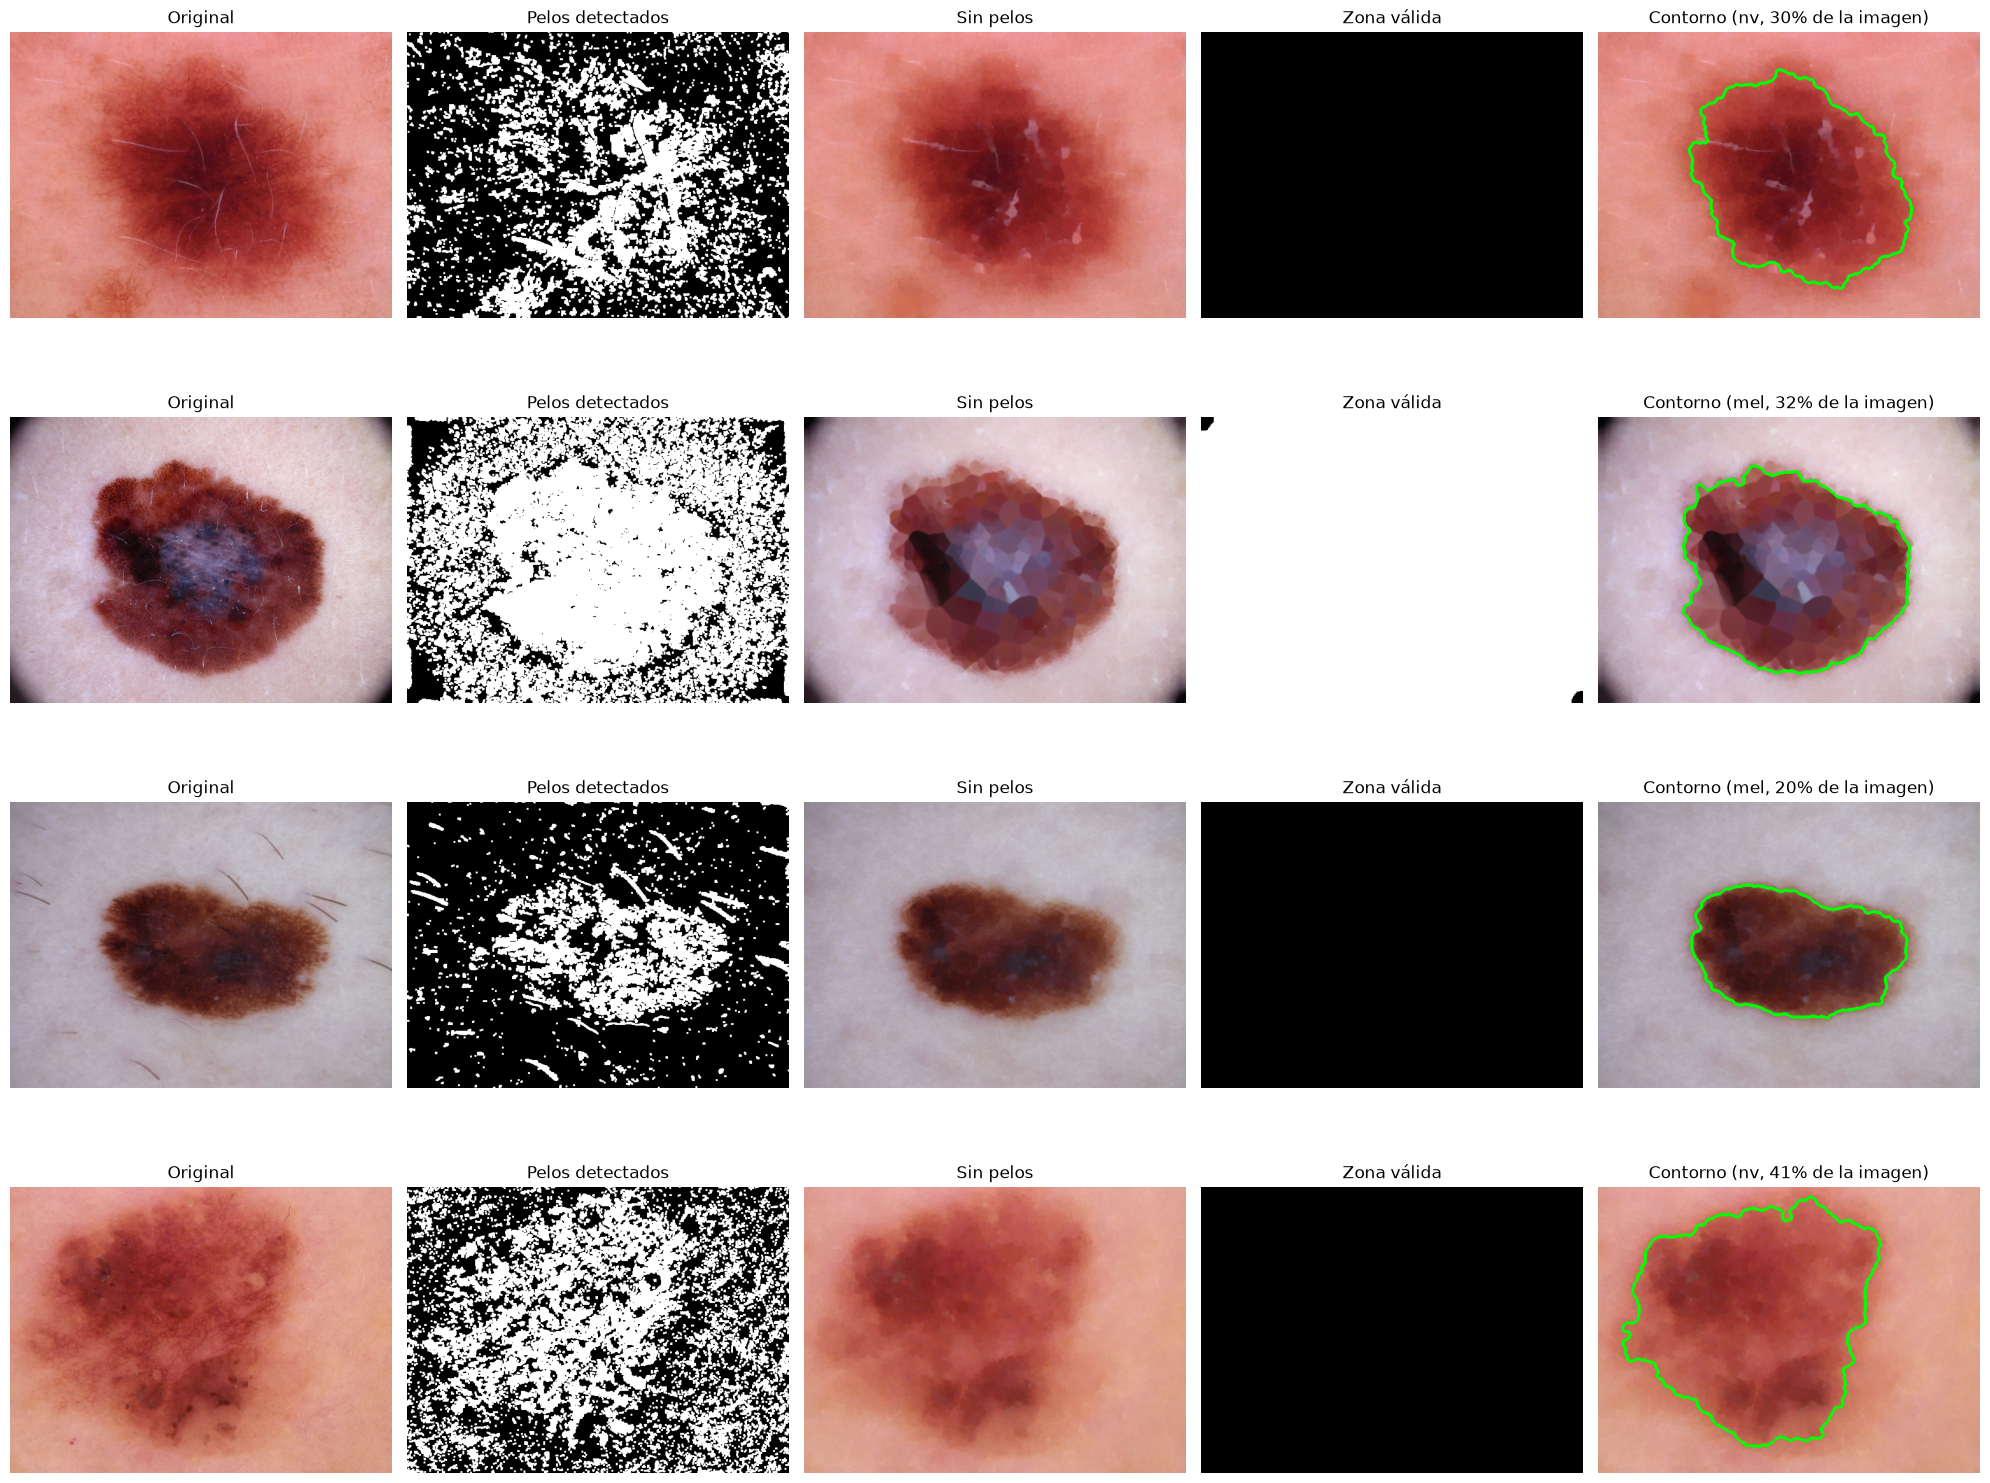

In [3]:
def dibujar_contorno(img, mascara):
    salida = img.copy()
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(salida, contornos, -1, (0, 255, 0), 3)
    return salida


def mostrar(muestras):
    if len(muestras) == 0:
        print("No hay imágenes para mostrar")
        return

    titulos = ["Original", "Pelos detectados", "Sin pelos", "Zona válida", "Contorno"]
    fig, axs = plt.subplots(len(muestras), 5, figsize=(20, 4 * len(muestras)), squeeze=False)
    for fila_ax, (_, fila) in zip(axs, muestras.iterrows()):
        img = cargar(fila["image_id"])
        limpia, m_pelos, valida, lesion = procesar(img)
        fraccion = (lesion > 0).mean() * 100

        fila_ax[0].imshow(img)
        fila_ax[1].imshow(m_pelos, cmap="gray")
        fila_ax[2].imshow(limpia)
        fila_ax[3].imshow(valida, cmap="gray")
        fila_ax[4].imshow(dibujar_contorno(limpia, lesion))
        for ax, t in zip(fila_ax, titulos):
            ax.set_title(t)
            ax.axis("off")
        fila_ax[4].set_title(f"Contorno ({fila['dx']}, {fraccion:.0f}% de la imagen)")
    plt.tight_layout()
    plt.show()


muestras = train_df.sample(4, random_state=1)
mostrar(muestras)

Vacías (<1%): 0
Sospechosas (>70%): 0
Mediana: 0.14375185185185185


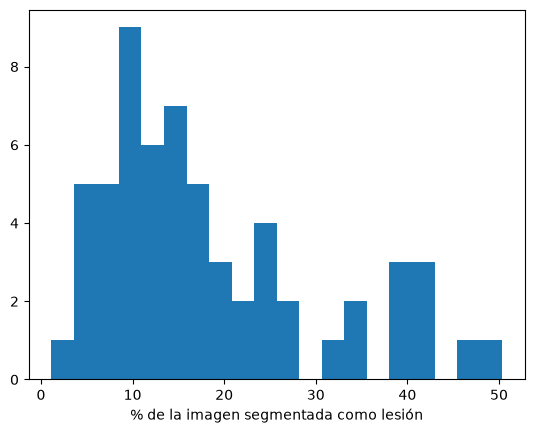

In [4]:
muestra_grande = train_df.sample(60, random_state=7)
fracciones = []
for _, fila in muestra_grande.iterrows():
    img = cargar(fila["image_id"])
    _, _, _, lesion = procesar(img)
    fracciones.append((lesion > 0).mean())

fracciones = np.array(fracciones)
print("Vacías (<1%):", (fracciones < 0.01).sum())
print("Sospechosas (>70%):", (fracciones > 0.70).sum())
print("Mediana:", np.median(fracciones))

plt.hist(fracciones * 100, bins=20)
plt.xlabel("% de la imagen segmentada como lesión")
plt.show()

1 5


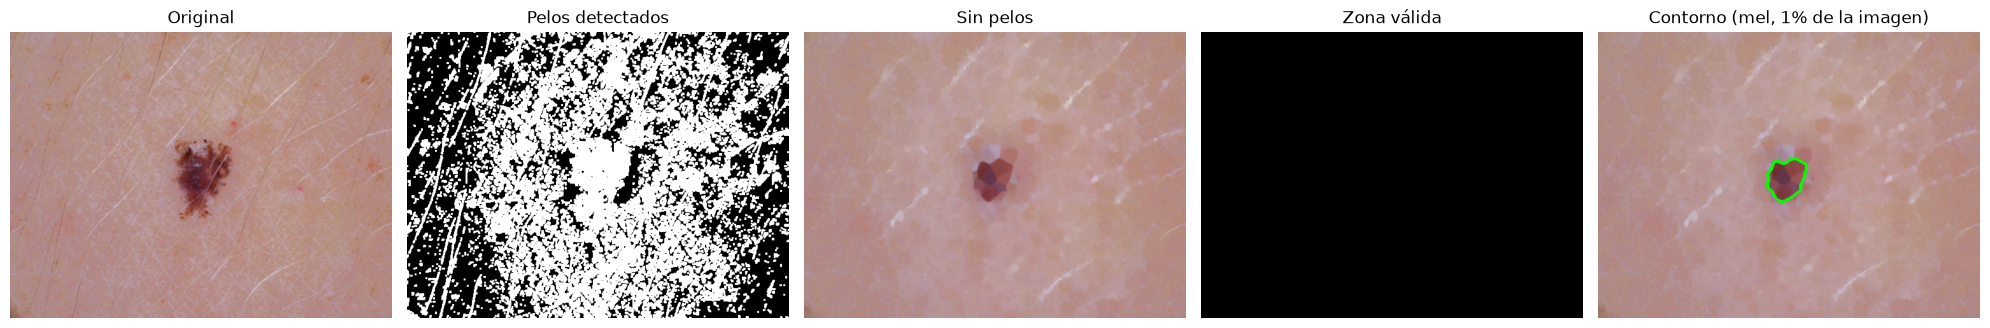

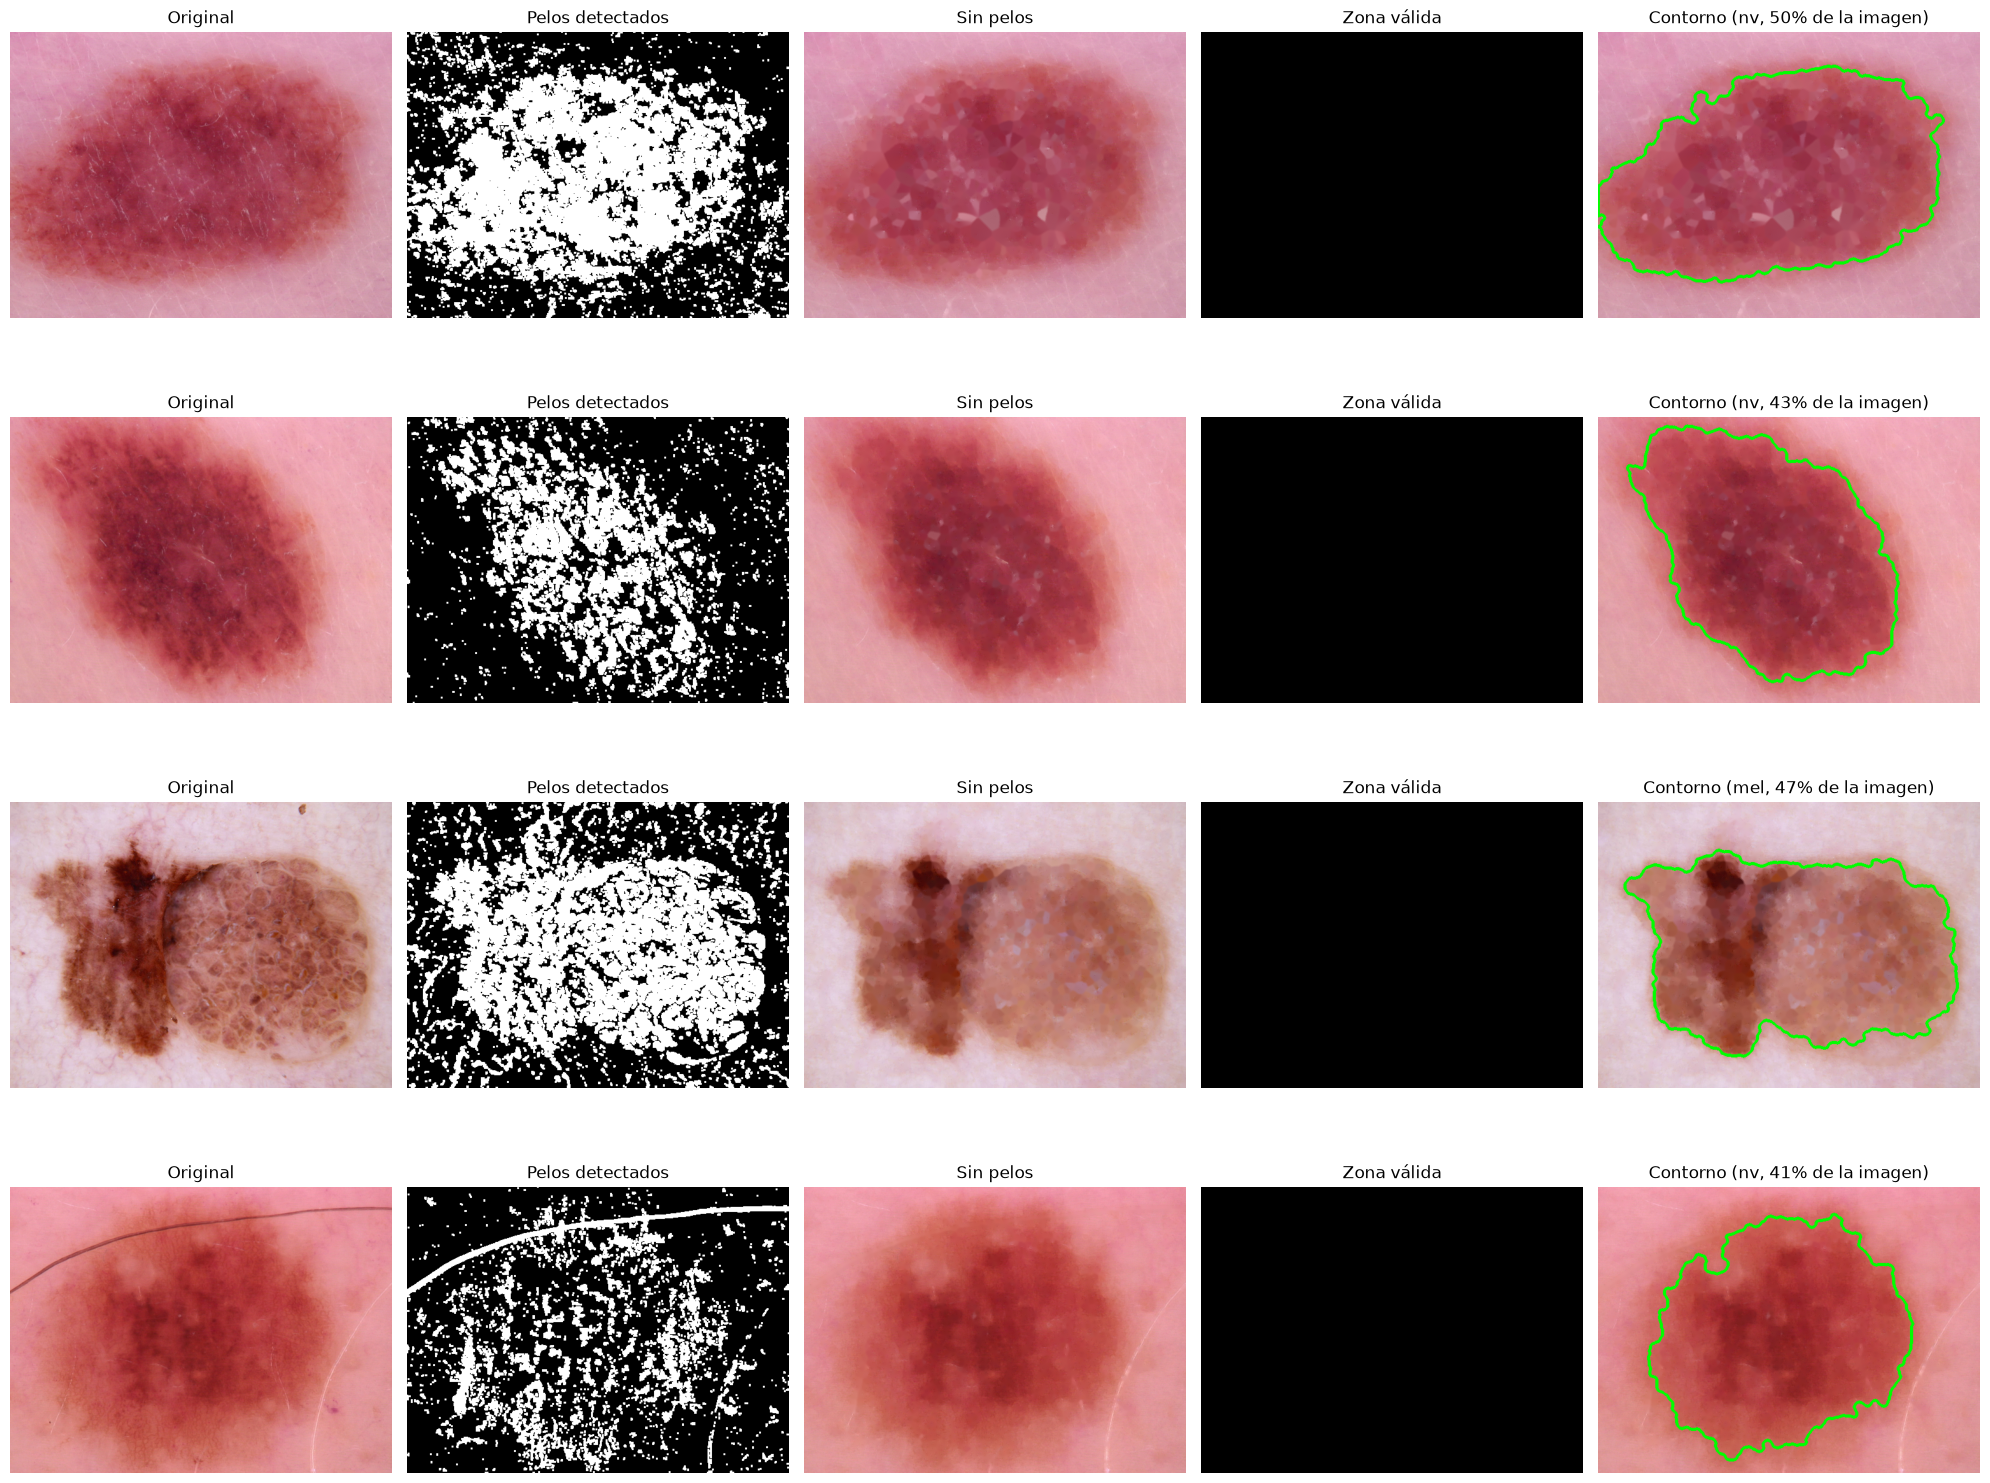

In [5]:
muestra_grande = train_df.sample(60, random_state=7).copy()
muestra_grande["fraccion"] = fracciones

chicas = muestra_grande[muestra_grande["fraccion"] < 0.04]
grandes = muestra_grande[muestra_grande["fraccion"] > 0.40]
print(len(chicas), len(grandes))

mostrar(chicas.head(4))
mostrar(grandes.head(4))